# Figures

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea, VPacker
from matplotlib.patches import Circle, FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import FormatStrFormatter, MaxNLocator, MultipleLocator

SOURCE = "data/source_data.xlsx"
sheets = pd.read_excel(SOURCE, sheet_name=None)
Path("figures").mkdir(exist_ok=True)

ORDER = ["NO2", "F", "OH", "CO2Me", "CHO", "CN", "COOH", "Cl", "NH2", "NMe2"]
COLOR = dict(zip(ORDER, ["#9100FF", "#8C5400", "#BCDD00", "#F20096", "#FF7900",
                         "#0ABE5A", "#FF0000", "#00FF00", "#0000FF", "#00DEF0"]))
TRAINING = {"Combined": "#C8312E", "Synthetic-only": "#2C6FB7", "Experimental-only": "#A0A0A0"}
OUTCOME = {"Found": "#1F9779", "Correct rejection": "#C8EDE0", "Missed": "#D55E00", "False detection": "#FDC98A"}
MARK = {"Corrected": "o", "Introduced error": "x"}
BAND = "#E5EEF6"
WN = "Wavenumber (cm-1)"
WN_LABEL = "Wavenumber (cm$^{-1}$)"
BINARY = [f"2-{i}" for i in range(1, 11)]
FOUR = [f"4-{i}" for i in range(1, 6)]
SIX = [f"6-{i}" for i in range(1, 6)]
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 7,
                     "axes.linewidth": 0.6, "lines.linewidth": 0.8, "xtick.major.width": 0.6,
                     "ytick.major.width": 0.6, "xtick.minor.width": 0.5, "xtick.major.size": 2.5,
                     "ytick.major.size": 2.5, "xtick.minor.size": 1.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.dpi": 120, "savefig.dpi": 300})


def group(name):
    return "−" + name.replace("2", "$_2$")


def page(width, height):
    fig = plt.figure(figsize=(width / 25.4, height / 25.4))
    mm = fig.add_axes([0, 0, 1, 1], xlim=(0, width), ylim=(height, 0), zorder=-1)
    mm.axis("off")
    return fig, mm


def axes(fig, left, top, width, height):
    w, h = fig.get_size_inches() * 25.4
    return fig.add_axes([left / w, 1 - (top + height) / h, width / w, height / h], facecolor="none")


def letters(mm, places):
    for letter, (x, y) in places.items():
        mm.text(x, y, letter, fontsize=10, fontweight="bold", va="top")


def formula(ax, x, y, lines, loc="center", align="center", weight="bold", size=7):
    rows = []
    for tokens in lines:
        parts, previous = [], None
        for token in tokens:
            if token in COLOR:
                if previous in COLOR:
                    parts.append(TextArea(" + ", textprops={"size": size}))
                parts.append(TextArea(group(token), textprops={"size": size, "color": COLOR[token], "weight": weight}))
            elif isinstance(token, tuple):
                parts.append(TextArea(token[0], textprops={"size": size, "color": token[1], "weight": weight}))
            else:
                parts.append(TextArea(token, textprops={"size": size}))
            previous = token
        rows.append(HPacker(children=parts, align="baseline", pad=0, sep=0))
    ax.add_artist(AnchoredOffsetbox(loc, child=VPacker(children=rows, align=align, pad=0, sep=1.5), frameon=False,
                                    bbox_to_anchor=(x, y), bbox_transform=ax.transData, pad=0, borderpad=0))


def color_ticks(labels, names):
    for label, name in zip(labels, names):
        label.set_color(COLOR[name])
        label.set_fontweight("bold")


def outcome_grid(ax, outcomes, changes):
    ax.imshow([[list(OUTCOME).index(o) for o in row] for row in outcomes], cmap=ListedColormap(list(OUTCOME.values())),
              vmin=-0.5, vmax=3.5, aspect="auto")
    n, m = len(outcomes), len(outcomes[0])
    ax.hlines(np.arange(n + 1) - 0.5, -0.5, m - 0.5, color="white", lw=0.6)
    ax.vlines(np.arange(m + 1) - 0.5, -0.5, n - 0.5, color="white", lw=0.6)
    for i, row in enumerate(changes):
        for j, change in enumerate(row):
            if change in MARK:
                ax.plot(j, i, MARK[change], color="black", mfc="none", ms=4, mew=0.8)


def call_blocks(fig, mm, calls, left, right, top, change=None, width=74, height=49, gap=2):
    table = calls.set_index(["Mixture", "Compound"])
    half = (height - gap) / 2
    for mixtures, x, y, h, x_axis in ((BINARY, left, top, height, True), (FOUR, right, top, half, False),
                                      (SIX, right, top + half + gap, half, True)):
        ax = axes(fig, x, y, width, h)
        outcomes = [[table.loc[(m, c), "Outcome"] for c in ORDER] for m in mixtures]
        changes = [[table.loc[(m, c), change] if change else "" for c in ORDER] for m in mixtures]
        outcome_grid(ax, outcomes, changes)
        ax.set_yticks(range(len(mixtures)), mixtures)
        ax.spines["bottom"].set_visible(x_axis)
        ax.set_xticks(range(len(ORDER)), [group(c) for c in ORDER] if x_axis else [], rotation=90)
        ax.tick_params(bottom=x_axis)
        color_ticks(ax.get_xticklabels(), ORDER)
    for x, title in ((left, "Binary mixtures"), (right, "Four- and six-component mixtures")):
        mm.text(x + width / 2, top - 1.5, title, ha="center", va="bottom", fontsize=7.5)
    mm.text(left - 8, top + height / 2, "Mixture ID", rotation=90, ha="center", va="center", fontsize=7.5)
    mm.text((left + right + width) / 2, top + height + 11.5, "Functional group", ha="center", va="top", fontsize=7.5)


def outcome_key(mm, x, y, order, marks=False, size=7, spacing=3, handle=1.5):
    handles = [Patch(color=OUTCOME[name], label=name) for name in order]
    if marks:
        handles += [Line2D([], [], ls="", marker=MARK[k], mfc="none", color="black", label=k) for k in MARK]
    mm.figure.legend(handles=handles, loc="center", bbox_to_anchor=(x, y), bbox_transform=mm.transData,
                     ncol=len(handles), fontsize=size, handlelength=handle, handleheight=1, columnspacing=spacing)

## Figure 1

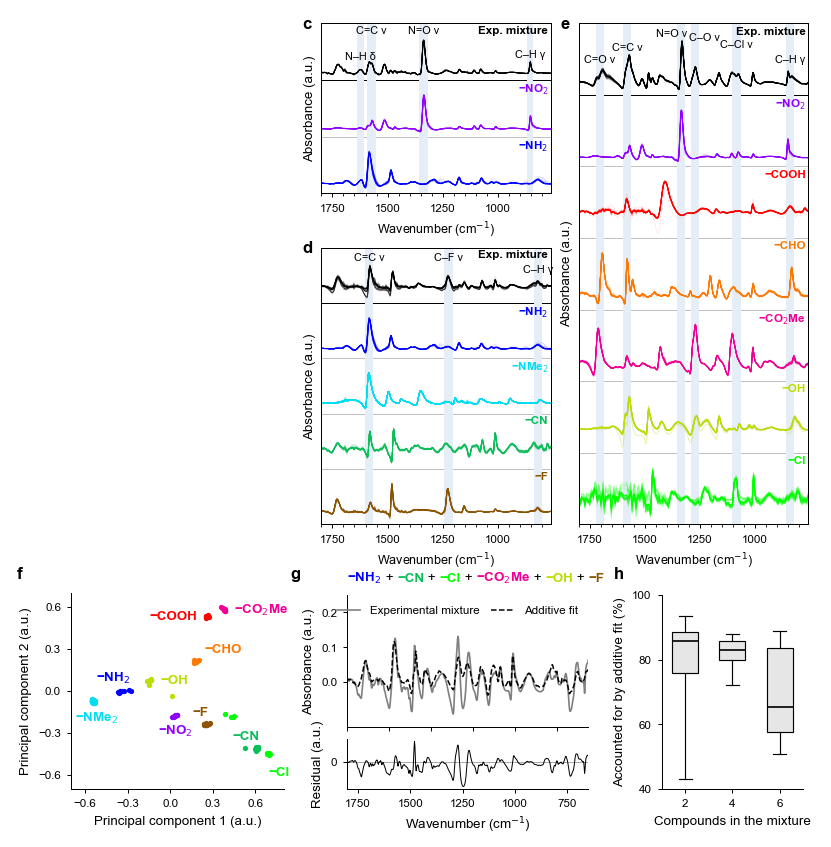

In [2]:
fig, mm = page(171, 174)
letters(mm, {"c": (61.5, 1), "d": (61.5, 48.5), "e": (116, 1), "f": (1, 117.5), "g": (59, 117.5), "h": (127.5, 117.5)})
MM = 72 / 25.4
BANDS = {"Fig. 1c": [(1606, 1640, "N–H δ", 6, 0), (1554, 1593, "C=C ν", 0.5, 0), (1317, 1355, "N=O ν", 0.5, 0),
                     (839, 867, "C–H γ", 5.5, 0)],
         "Fig. 1d": [(1564, 1601, "C=C ν", 1, 0), (1205, 1243, "C–F ν", 1, 0), (799, 837, "C–H γ", 3.5, 0)],
         "Fig. 1e": [(1686, 1724, "C=O ν", 6.5, 0), (1562, 1601, "C=C ν", 4, 0), (1317, 1354, "N=O ν", 1, -2),
                     (1254, 1293, "C–O ν", 2, 2), (1064, 1103, "C–Cl ν", 3.5, 0), (822, 861, "C–H γ", 6.5, 0)]}
PANELS = {"Fig. 1c": (65.5, 2.5, 38.5), "Fig. 1d": (65.5, 50, 108.5), "Fig. 1e": (120, 2.5, 108.5)}
for sheet, (left, top, bottom) in PANELS.items():
    table = sheets[sheet]
    samples = [c.removesuffix(" mean spectrum (a.u.)") for c in table.columns if c.endswith(" mean spectrum (a.u.)")]
    height = (bottom - top) / len(samples)
    for row, sample in enumerate(samples):
        mix, last = row == 0, row == len(samples) - 1
        ax = axes(fig, left, top + row * height, 48.5, height)
        color = "black" if mix else COLOR[sample[1:]]
        every = table.filter(regex=f"^{re.escape(sample)} spectrum \\d+").to_numpy()
        ax.plot(table[WN], every, color=color, lw=0.5, alpha=0.1)
        ax.plot(table[WN], table[f"{sample} mean spectrum (a.u.)"], color=color, lw=0.7)
        above, below = (3.5, 1) if mix else (3, 1)
        per_mm = np.ptp(every) / (height - above - below)
        ax.set(xlim=(1800, 760), ylim=(every.min() - below * per_mm, every.max() + above * per_mm), yticks=[])
        for low, high, label, depth, shift in BANDS[sheet]:
            ax.axvspan(low, high, color=BAND, lw=0, zorder=0)
            if mix:
                ax.annotate(label, ((low + high) / 2, 1), xycoords=("data", "axes fraction"),
                            xytext=(shift * MM, -depth * MM), textcoords="offset points", ha="center", va="top",
                            fontsize=6.5)
        ax.text(0.99, 0.96, "Exp. mixture" if mix else group(sample[1:]), color=color, fontweight="bold",
                transform=ax.transAxes, ha="right", va="top")
        ax.spines[["top", "right"]].set_visible(True)
        ax.spines["top"].set_visible(mix)
        ax.spines["bottom"].set_color("black" if mix or last else "0.75")
        ax.tick_params(which="both", bottom=last, labelbottom=last)
        if last:
            ax.set_xticks([1750, 1500, 1250, 1000])
            ax.xaxis.set_minor_locator(MultipleLocator(50))
            ax.set_xlabel(WN_LABEL, fontsize=7.5)
    mm.text(left - 2.5, (top + bottom) / 2, "Absorbance (a.u.)", rotation=90, ha="center", va="center", fontsize=8)

pca = sheets["Fig. 1f"]
f = axes(fig, 12.5, 123, 45, 41.5)
PLACE = {"NO2": (0, -9, "center"), "F": (-3, 7, "center"), "OH": (6, 0, "left"), "CO2Me": (6, 0, "left"),
         "CHO": (5, 7, "left"), "CN": (-6, 7, "center"), "COOH": (-6, 0, "right"), "Cl": (7, -12, "center"),
         "NH2": (-4, 8, "center"), "NMe2": (2, -10, "center")}
for c in ORDER:
    points = pca[pca["Compound"] == c]
    x, y = points["Principal component 1 (a.u.)"], points["Principal component 2 (a.u.)"]
    f.scatter(x, y, s=10, color=COLOR[c], lw=0)
    dx, dy, ha = PLACE[c]
    f.annotate(group(c), (x.median(), y.median()), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center",
               color=COLOR[c], fontweight="bold", fontsize=8)
ticks = [-0.6, -0.3, 0, 0.3, 0.6]
f.set(xlim=(-0.7, 0.8), ylim=(-0.7, 0.7), xticks=ticks, yticks=ticks)
f.set_xlabel("Principal component 1 (a.u.)", fontsize=8)
f.set_ylabel("Principal component 2 (a.u.)", fontsize=8)

fit = sheets["Fig. 1g"]
g = axes(fig, 71, 123.5, 51, 28)
g.plot(fit[WN], fit["Mixture 6-2 mean spectrum (a.u.)"], color="gray", lw=1, label="Experimental mixture")
g.plot(fit[WN], fit["Additive fit (a.u.)"], "k--", lw=0.9, label="Additive fit")
g.set(xlim=(1800, 650), ylim=(-0.13, 0.25), yticks=[0, 0.1, 0.2], xticklabels=[])
g.set_ylabel("Absorbance (a.u.)", fontsize=8)
g.legend(loc="upper right", ncol=2, fontsize=7, handlelength=2, columnspacing=1)
residual = axes(fig, 71, 154, 51, 10.5)
residual.axhline(0, color="0.6", lw=0.5)
residual.plot(fit[WN], fit["Residual (a.u.)"], color="black", lw=0.6)
residual.set(xlim=(1800, 650), yticks=[0], xticks=[1750, 1500, 1250, 1000, 750])
residual.set_ylabel("Residual (a.u.)", fontsize=8)
residual.set_xlabel(WN_LABEL, fontsize=8)
formula(mm, 71, 120, [["NH2", "CN", "Cl", "CO2Me", "OH", "F"]], loc="center left", size=8)

values = sheets["Fig. 1h"]
h = axes(fig, 137.5, 123.5, 30, 41)
sizes = sorted(values["Compounds in the mixture"].unique())
h.boxplot([values.loc[values["Compounds in the mixture"] == n, "Accounted for by additive fit (%)"] for n in sizes],
          tick_labels=sizes, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True,
          boxprops={"facecolor": "#E6E6E6", "lw": 0.7}, medianprops={"color": "black", "lw": 1},
          whiskerprops={"lw": 0.7}, capprops={"lw": 0.7})
h.set(ylim=(40, 100), yticks=[40, 60, 80, 100])
h.set_xlabel("Compounds in the mixture", fontsize=8)
h.set_ylabel("Accounted for by additive fit (%)", fontsize=8)
fig.savefig("figures/figure_1.png")
plt.show()

## Figure 2

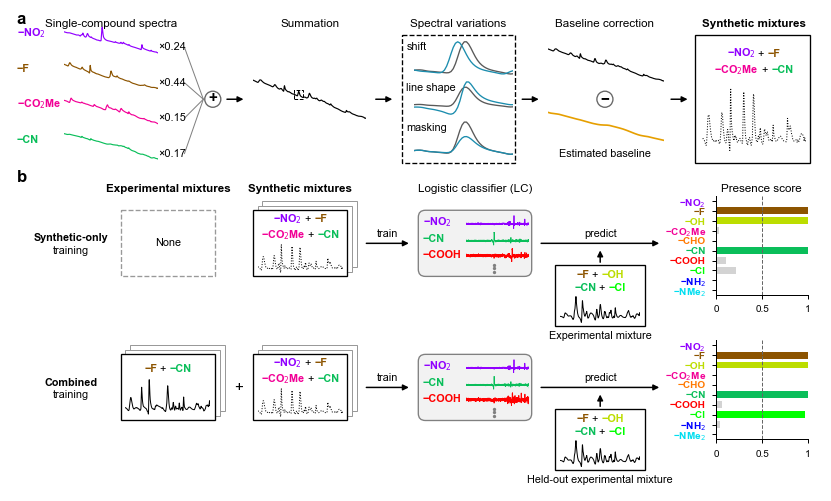

In [3]:
fig, mm = page(171, 101)
letters(mm, {"a": (1, 0), "b": (1, 33.5)})
steps, close, examples = sheets["Fig. 2a"], sheets["Fig. 2a close-ups"], sheets["Fig. 2b spectra"]
weights, scores = sheets["Fig. 2b LC weights"], sheets["Fig. 2b scores"].set_index("Compound")


def trace(left, top, width, height, table, column, xlim=(1800, 650), **style):
    ax = axes(fig, left, top, width, height)
    ax.plot(table[WN], table[column], **style)
    ax.set_xlim(*xlim)
    ax.axis("off")
    return ax


def arrow(x0, y0, x1, y1):
    mm.annotate("", (x1, y1), (x0, y0), arrowprops={"arrowstyle": "-|>", "color": "black", "lw": 0.9,
                                                    "shrinkA": 0, "shrinkB": 0, "mutation_scale": 7})


def frame(left, top, width, height, stack=False, **style):
    for k in (2, 1) if stack else ():
        mm.add_patch(Rectangle((left + k, top - k), width, height, fc="white", ec="0.6", lw=0.6))
    mm.add_patch(Rectangle((left, top), width, height, **{"fc": "white", "ec": "black", "lw": 0.8, **style}))


def operator(x, y, sign):
    mm.add_patch(Circle((x, y), 1.7, fc="white", ec="0.4", lw=0.8))
    mm.text(x, y, sign, ha="center", va="center", fontsize=9, fontweight="bold")


for x, label in ((21, "Single-compound spectra"), (63, "Summation"), (94.5, "Spectral variations"),
                 (125.5, "Baseline correction")):
    mm.text(x, 2.5, label, ha="center", va="center", fontsize=7)
mm.text(157, 2.5, "Synthetic mixtures", ha="center", va="center", fontsize=7, fontweight="bold")
for k, column in enumerate(c for c in steps.columns if " weight " in c):
    name, weight, y = column.split()[0][1:], column.split()[2], 5.5 + 7.5 * k
    trace(11, y - 2.5, 20, 6, steps, column, color=COLOR[name], lw=0.7)
    mm.text(1, y - 1, group(name), color=COLOR[name], fontweight="bold", va="center", fontsize=6.5)
    mm.text(31, y + 2, f"×{weight}", va="center", fontsize=6.5)
    mm.plot([36.5, 40.5], [y + 2, 18.5], color="0.5", lw=0.6)
operator(42.5, 18.5, "+")
for x0 in (45.5, 77, 108, 139.5):
    arrow(x0, 18.5, x0 + 3.5, 18.5)
total = trace(51, 14, 24, 9, steps, "Weighted sum (a.u.)", color="black", lw=0.7)
near = steps.loc[steps[WN].between(1292, 1382), "Weighted sum (a.u.)"]
pad = 0.05 * np.ptp(steps["Weighted sum (a.u.)"])
total.add_patch(Rectangle((1382, near.min() - pad), -90, np.ptp(near) + 2 * pad, fill=False, ls="--", lw=0.6))
frame(82.5, 5, 24, 27, ls="--")
for k, (column, label) in enumerate((("Shift by 7 cm-1 (a.u.)", "shift"), ("Line shape (a.u.)", "line shape"),
                                     ("Masking (a.u.)", "masking"))):
    ax = trace(85, 6 + 8.5 * k, 21, 7.5, close, "Before (a.u.)", xlim=(1382, 1292), color="0.35", lw=0.8)
    ax.plot(close[WN], close[column], color="#1C8DAE", lw=0.8)
    mm.text(83.5, 7.5 + 8.5 * k, label, va="center", fontsize=6.5)
trace(113.5, 7.5, 24.5, 7.5, steps, "Weighted sum (a.u.)", color="black", lw=0.7)
operator(125.5, 18.5, "−")
trace(113.5, 21, 24.5, 6.5, steps, "Estimated baseline (a.u.)", color="#E69F00", lw=1)
mm.text(125.5, 30, "Estimated baseline", ha="center", va="center", fontsize=6.5)
frame(144.5, 5, 24.5, 27)
formula(mm, 157, 10.5, [["NO2", "F"], ["CO2Me", "CN"]], size=6.5)
trace(146, 15.5, 22, 14.5, steps, "Synthetic mixture (a.u.)", color="black", lw=0.6, ls=":")

for x, label, weight in ((33, "Experimental mixtures", "bold"), (61, "Synthetic mixtures", "bold"),
                         (98, "Logistic classifier (LC)", "normal"), (158.5, "Presence score", "normal")):
    mm.text(x, 37.5, label, ha="center", va="center", fontsize=7, fontweight=weight)
for training, top, model, caption in (("Synthetic-only", 42, "Synthetic-only LC", "Experimental mixture"),
                                      ("Combined", 72.5, "Combined LC without 4-4", "Held-out experimental mixture")):
    middle, below = top + 7, top + 11.5
    mm.text(12.5, middle, training, ha="center", va="bottom", fontsize=6.5, fontweight="bold")
    mm.text(12.5, middle + 0.5, "training", ha="center", va="top", fontsize=6.5)
    if training == "Combined":
        frame(23, top, 20, 14, stack=True)
        formula(mm, 33, top + 3, [["F", "CN"]], size=6.5)
        trace(24, top + 5, 18, 8, examples, "Mixture 2-3 mean spectrum (a.u.)", color="black", lw=0.6)
        mm.text(48, middle, "+", ha="center", va="center", fontsize=9)
    else:
        frame(23, top, 20, 14, ls="--", ec="0.6")
        mm.text(33, middle, "None", ha="center", va="center", fontsize=6.5)
    frame(51, top, 20, 14, stack=True)
    formula(mm, 61, top + 3.5, [["NO2", "F"], ["CO2Me", "CN"]], size=6.5)
    trace(52, top + 7, 18, 6.5, examples, "Synthetic mixture (a.u.)", color="black", lw=0.6, ls=":")
    arrow(75, middle, 84, middle)
    mm.text(79.5, middle - 1, "train", ha="center", va="bottom", fontsize=6.5)
    mm.add_patch(FancyBboxPatch((86, top), 24, 14, boxstyle="round,pad=0,rounding_size=1.5", fc="#F2F2F2", ec="0.5",
                                lw=0.8))
    for k, name in enumerate(["NO2", "CN", "COOH"]):
        y = top + 2.5 + 3.5 * k
        mm.text(87, y, group(name), color=COLOR[name], fontweight="bold", va="center", fontsize=6.5)
        trace(96, y - 1.5, 13.5, 3, weights, f"-{name} weight, {model} (scaled)", xlim=(3500, 650), color=COLOR[name],
              lw=0.5)
    mm.plot([102] * 3, np.linspace(top + 11.5, top + 13, 3), "o", color="0.5", ms=1)
    arrow(112, middle, 137, middle)
    mm.text(124.5, middle - 1, "predict", ha="center", va="bottom", fontsize=6.5)
    arrow(124.5, below - 0.5, 124.5, middle + 1.5)
    frame(115, below, 19, 13)
    formula(mm, 124.5, below + 3.5, [["F", "OH"], ["CN", "Cl"]], size=6.5)
    trace(116, below + 6.5, 17, 6, examples, "Mixture 4-4 mean spectrum (a.u.)", color="black", lw=0.6)
    mm.text(124.5, below + 15, caption, ha="center", va="center", fontsize=6.5)
    ax = axes(fig, 149, top - 3, 19.5, 21)
    values = scores.loc[ORDER, f"{training} presence score"]
    ax.barh(range(len(ORDER)), values, height=0.7,
            color=[COLOR[c] if v >= 0.5 else "#D3D3D3" for c, v in values.items()])
    ax.axvline(0.5, color="0.4", ls="--", lw=0.6)
    ax.set(xlim=(0, 1), ylim=(len(ORDER) - 0.5, -0.5), xticks=[0, 0.5, 1], xticklabels=["0", "0.5", "1"])
    ax.set_yticks(range(len(ORDER)), [group(c) for c in ORDER])
    ax.tick_params(labelsize=6)
    color_ticks(ax.get_yticklabels(), ORDER)
fig.savefig("figures/figure_2.png")
plt.show()

## Figure 3

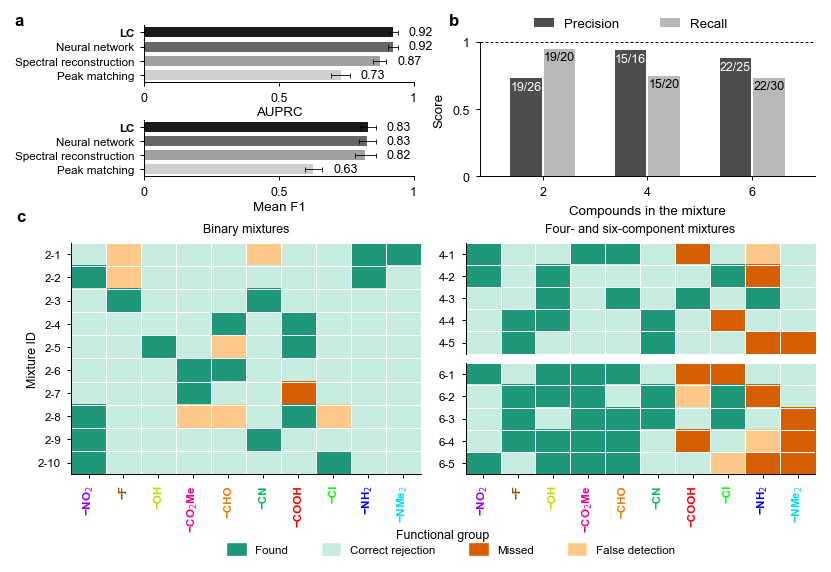

In [4]:
fig, mm = page(171, 116)
letters(mm, {"a": (0.5, 0.5), "b": (92.5, 0.5), "c": (1, 42)})
methods = sheets["Fig. 3a"]
names = ["LC" if m == "Logistic classifier" else m for m in methods["Method"]]
for top, measure in ((3, "AUPRC"), (23, "Mean F1")):
    ax = axes(fig, 28, top, 57, 12)
    values, sd = methods[measure], methods[f"{measure} SD"]
    ax.barh(range(4), values, height=0.7, color=["#1A1A1A", "#666666", "#A0A0A0", "#CFCFCF"], xerr=sd,
            error_kw={"lw": 0.5, "capsize": 1.5, "capthick": 0.5})
    for k, (value, s) in enumerate(zip(values, sd)):
        ax.text(value + s + 0.04, k, f"{value:.2f}", va="center", fontsize=7.5)
    ax.set(xlim=(0, 1), ylim=(3.5, -0.5), xticks=[0, 0.5, 1], xticklabels=["0", "0.5", "1"])
    ax.set_yticks(range(4), names)
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.tick_params(axis="x", labelsize=7.5)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel(measure, fontsize=8, labelpad=1.5)

sizes = sheets["Fig. 3b"]
ax = axes(fig, 99, 6.5, 71, 28.5)
for shift, measure, color, ink, total in ((-0.16, "Precision", "#4D4D4D", "white", "Positive calls"),
                                          (0.16, "Recall", "#B9B9B9", "black", "Present compounds")):
    ax.bar(np.arange(3) + shift, sizes[measure], width=0.3, color=color, label=measure)
    for k, (value, found, n) in enumerate(zip(sizes[measure], sizes["Found"], sizes[total])):
        ax.text(k + shift, value - 0.02, f"{found}/{n}", ha="center", va="top", color=ink, fontsize=7.5)
ax.axhline(1, color="black", lw=0.6, ls=(0, (3, 2)))
ax.set(xlim=(-0.6, 2.6), ylim=(0, 1), xticks=[0, 1, 2], xticklabels=sizes["Compounds in the mixture"],
       yticks=[0, 0.5, 1], yticklabels=["0", "0.5", "1"])
ax.tick_params(labelsize=7.5)
ax.set_xlabel("Compounds in the mixture", fontsize=8)
ax.set_ylabel("Score", fontsize=8)
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1), ncol=2, fontsize=8, handlelength=1.5, columnspacing=3)

call_blocks(fig, mm, sheets["Fig. 3c"], left=12.5, right=96, top=49)
outcome_key(mm, 93, 114, ["Found", "Correct rejection", "Missed", "False detection"])
fig.savefig("figures/figure_3.png")
plt.show()

## Figure 4

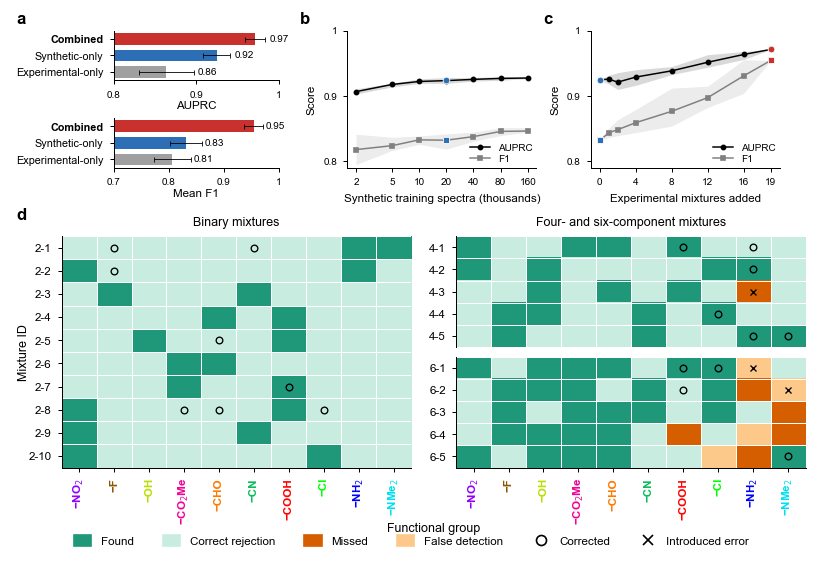

In [5]:
fig, mm = page(169, 115)
letters(mm, {"a": (1, 0), "b": (61, 0), "c": (112.5, 0), "d": (1, 41.5)})
conditions = sheets["Fig. 4a"]
for top, measure, start, ticks in ((4, "AUPRC", 0.8, [0.8, 0.9, 1]), (22.5, "Mean F1", 0.7, [0.7, 0.8, 0.9, 1])):
    ax = axes(fig, 21.5, top, 35, 10.5)
    values, sd = conditions[measure], conditions[f"{measure} SD"]
    ax.barh(range(3), values - start, left=start, height=0.7, color=[TRAINING[t] for t in conditions["Training"]],
            xerr=sd, error_kw={"lw": 0.5, "capsize": 1.5, "capthick": 0.5})
    for k, (value, s) in enumerate(zip(values, sd)):
        ax.text(value + s + 0.005, k, f"{value:.2f}", va="center", fontsize=6)
    ax.set(xlim=(start, 1), ylim=(2.5, -0.5), xticks=ticks, xticklabels=[f"{t:g}" for t in ticks])
    ax.set_yticks(range(3), conditions["Training"], fontsize=6.5)
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.tick_params(axis="x", labelsize=6)
    ax.set_xlabel(measure, fontsize=7, labelpad=1)

for left, sheet, x_name in ((71, "Fig. 4b", "Synthetic training spectra"),
                            (122.5, "Fig. 4c", "Experimental mixtures added")):
    curve = sheets[sheet]
    ax = axes(fig, left, 4, 40, 29)
    for measure, color, marker, label in (("AUPRC", "black", "o", "AUPRC"), ("Mean F1", "gray", "s", "F1")):
        points = curve[curve["Measure"] == measure].sort_values(x_name)
        line = points[~points["Training"].str.contains("main text")]
        ax.fill_between(line[x_name], line["Minimum"], line["Maximum"], color=color, alpha=0.15, lw=0)
        ax.plot(line[x_name], line["Mean"], color=color, lw=0.9, marker=marker, ms=2.5, label=label)
        for _, row in points[~points["Training"].str.contains("sets|subsets")].iterrows():
            ax.plot(row[x_name], row["Mean"], marker=marker, ms=4, mfc=TRAINING[row["Training"].split(",")[0]],
                    mec="white", mew=0.5)
    ax.set(ylim=(0.79, 1), yticks=[0.8, 0.9, 1], yticklabels=["0.8", "0.9", "1"])
    ax.tick_params(labelsize=6)
    ax.set_ylabel("Score", fontsize=7)
    ax.legend(loc="lower right", fontsize=6, handlelength=2, labelspacing=0.2, borderaxespad=0)
    if sheet == "Fig. 4b":
        sizes = sorted(line[x_name].unique())
        ax.set(xscale="log", xticks=sizes, xticklabels=[f"{n // 1000}" for n in sizes])
        ax.minorticks_off()
        ax.set_xlabel("Synthetic training spectra (thousands)", fontsize=7)
    else:
        ax.set(xlim=(-1, 20), xticks=[0, 4, 8, 12, 16, 19])
        ax.set_xlabel(x_name, fontsize=7)

call_blocks(fig, mm, sheets["Fig. 4d"], left=10.5, right=94, top=47.5, change="Change")
outcome_key(mm, 84.5, 112, ["Found", "Correct rejection", "Missed", "False detection"], marks=True, spacing=2.5)
fig.savefig("figures/figure_4.png")
plt.show()

## Figure 5

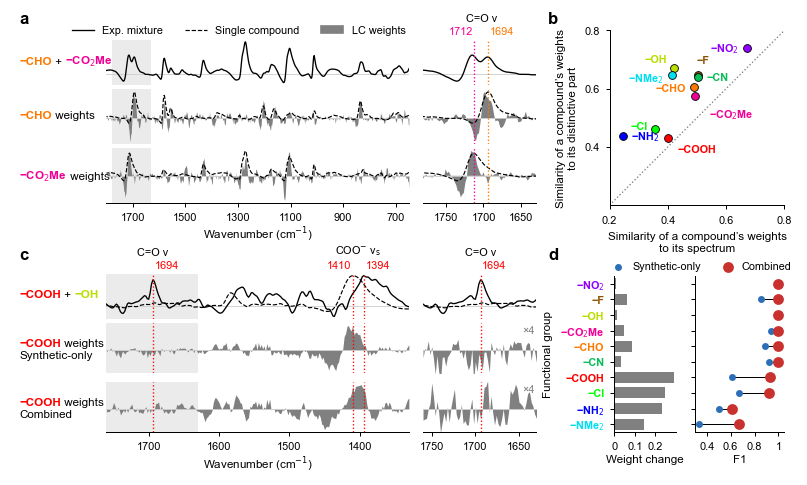

In [6]:
fig, mm = page(165, 97)
letters(mm, {"a": (1.5, 0), "b": (113.5, 0), "c": (1.5, 50), "d": (113.5, 50)})
band = sheets["Fig. 5 statistics"].set_index("Comparison")["Value"]
TOP = ("data", "axes fraction")


def spectrum_rows(table, tops, heights, rows, main, zoom, zoom_scale=1):
    pairs = []
    for top, height, (solid, dashed, filled) in zip(tops, heights, rows):
        shown = table[[c for c in (solid, dashed, filled) if c]].to_numpy()
        pad = 0.05 * np.ptp(shown)
        pair = []
        for left, width, xlim, scale in ((20, 64, main, 1), (87, 24, zoom, zoom_scale)):
            ax = axes(fig, left, top, width, height)
            ax.axhline(0, color="0.8", lw=0.5)
            if xlim == main:
                ax.axvspan(*zoom, color="#EBEBEB", lw=0, zorder=0)
            if filled:
                ax.fill_between(table[WN], scale * table[filled], color="gray", lw=0)
                if scale != 1:
                    ax.text(0.98, 0.95, f"×{scale}", transform=ax.transAxes, ha="right", va="top", color="gray",
                            fontsize=6.5)
            if dashed:
                ax.plot(table[WN], table[dashed], "k--", lw=0.7)
            if solid:
                ax.plot(table[WN], table[solid], color="black", lw=0.8)
            ax.set(xlim=xlim, ylim=(shown.min() - pad, shown.max() + pad), yticks=[])
            ax.spines["left"].set_visible(False)
            ax.spines["bottom"].set_visible(top == tops[-1])
            ax.tick_params(bottom=top == tops[-1], labelbottom=top == tops[-1], labelsize=6.5)
            pair.append(ax)
        pairs.append(pair)
    pairs[-1][0].set_xlabel(WN_LABEL, fontsize=7, labelpad=1.5)
    return pairs


def band_label(ax, position, text, color="black", ha="center", height=2):
    shift = {"left": 1, "right": -1, "center": 0}[ha]
    ax.annotate(text, (position, 1), xycoords=TOP, xytext=(shift, height), textcoords="offset points", ha=ha,
                va="bottom", color=color, fontsize=6.5)


panel_a = spectrum_rows(sheets["Fig. 5a"], (6, 16.5, 29), (9.5, 11.5, 11.5),
                        [("Mixture 2-6 spectrum (scaled)", None, None),
                         (None, "-CHO single-compound spectrum (scaled)",
                          "-CHO weight, Combined LC without 2-6 (scaled)"),
                         (None, "-CO2Me single-compound spectrum (scaled)",
                          "-CO2Me weight, Combined LC without 2-6 (scaled)")],
                        (1800, 650), (1780, 1630))
panel_a[-1][0].set_xticks([1700, 1500, 1300, 1100, 900, 700])
panel_a[-1][1].set_xticks([1750, 1700, 1650])
carbonyl = band[["-CO2Me C=O band", "-CHO C=O band"]]
for name, ha in (("CO2Me", "right"), ("CHO", "left")):
    position = band[f"-{name} C=O band"]
    for _, zoom in panel_a:
        zoom.axvline(position, color=COLOR[name], ls=":", lw=0.8)
    band_label(panel_a[0][1], position, f"{position:.0f}", COLOR[name], ha)
band_label(panel_a[0][1], carbonyl.mean(), "C=O ν", height=10)
formula(mm, 1.5, 10.5, [["CHO", "CO2Me"]], loc="center left", size=7)
formula(mm, 1.5, 22, [["CHO", " weights"]], loc="center left", size=7)
formula(mm, 1.5, 35, [["CO2Me", " weights"]], loc="center left", size=7)
fig.legend(handles=[Line2D([], [], color="black", lw=0.8, label="Exp. mixture"),
                    Line2D([], [], color="black", ls="--", lw=0.7, label="Single compound"),
                    Patch(color="gray", label="LC weights")], loc="center", bbox_to_anchor=(48, 4),
           bbox_transform=mm.transData, ncol=3, fontsize=6.5, handlelength=2, columnspacing=2)

similar = sheets["Fig. 5b"].set_index("Compound")
ax = axes(fig, 126.5, 4, 37, 37)
PLACE = {"NO2": (-5, 0, "right"), "F": (3, 9, "center"), "OH": (-4, 5, "right"), "CO2Me": (8, -11, "left"),
         "CHO": (-5, -1, "right"), "CN": (5, 0, "left"), "COOH": (6, -7, "left"), "Cl": (-4, 2, "right"),
         "NH2": (5, 0, "left"), "NMe2": (-5, -2, "right")}
for c in ORDER:
    x, y = similar.loc[c, "Similarity to spectrum"], similar.loc[c, "Similarity to distinctive part"]
    ax.scatter(x, y, s=22, color=COLOR[c], edgecolor="black", lw=0.5, zorder=3)
    dx, dy, ha = PLACE[c]
    ax.annotate(group(c), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", color=COLOR[c],
                fontweight="bold", fontsize=6.5)
ax.plot([0.2, 0.8], [0.2, 0.8], ":", color="gray", lw=0.8)
ax.set(xlim=(0.2, 0.8), ylim=(0.2, 0.8), xticks=[0.2, 0.4, 0.6, 0.8], yticks=[0.4, 0.6, 0.8])
ax.tick_params(labelsize=6.5)
ax.set_xlabel("Similarity of a compound’s weights\nto its spectrum", fontsize=7)
ax.set_ylabel("Similarity of a compound’s weights\nto its distinctive part", fontsize=7)

panel_c = spectrum_rows(sheets["Fig. 5c"], (55.5, 66, 78.5), (9.5, 10.5, 10.5),
                        [("Mixture 2-5 spectrum (scaled)", "-COOH single-compound spectrum (scaled)", None),
                         (None, None, "-COOH weight, Synthetic-only LC (scaled)"),
                         (None, None, "-COOH weight, mean Combined LC (scaled)")],
                        (1760, 1330), (1760, 1630), zoom_scale=4)
panel_c[-1][0].set_xticks([1700, 1600, 1500, 1400])
panel_c[-1][1].set_xticks([1750, 1700, 1650])
carboxylate = band[["-COOH carboxylate band", "Mixture 2-5 carboxylate band"]]
for j, ax in enumerate(panel_c[0]):
    low, high = sorted(ax.get_xlim())
    for name, ha in (("Mixture 2-5 C=O band", "left"), ("-COOH carboxylate band", "right"),
                     ("Mixture 2-5 carboxylate band", "left")):
        if low < band[name] < high:
            for row in panel_c:
                row[j].axvline(band[name], color="red", ls=":", lw=0.8)
            band_label(ax, band[name], f"{band[name]:.0f}", "red", ha)
    band_label(ax, band["Mixture 2-5 C=O band"], "C=O ν", height=10)
band_label(panel_c[0][0], carboxylate.mean(), "COO$^{-}$ ν$_\\mathrm{s}$", height=10)
formula(mm, 1.5, 60, [["COOH", "OH"]], loc="center left", size=7)
formula(mm, 1.5, 71.5, [["COOH", " weights"], ["Synthetic-only"]], loc="center left", align="left", size=7)
formula(mm, 1.5, 84, [["COOH", " weights"], ["Combined"]], loc="center left", align="left", size=7)

change = sheets["Fig. 5d"].set_index("Compound").loc[ORDER]
y = np.arange(len(ORDER))
bars = axes(fig, 127.5, 56, 13, 33)
bars.barh(y, change["Weight change"], height=0.7, color="gray")
bars.set(ylim=(len(ORDER) - 0.5, -0.5), xlim=(0, 0.3), xticks=[0, 0.1, 0.2], xticklabels=["0", "0.1", "0.2"])
bars.set_yticks(y, [group(c) for c in ORDER])
bars.tick_params(labelsize=6.5)
color_ticks(bars.get_yticklabels(), ORDER)
bars.set_xlabel("Weight change", fontsize=7, labelpad=1.5)
bars.set_ylabel("Functional group", fontsize=7)
f1 = axes(fig, 144.5, 56, 19, 33)
f1.hlines(y, change["F1, Synthetic-only LC"], change["F1, Combined LC"], color="black", lw=0.6)
f1.scatter(change["F1, Synthetic-only LC"], y, s=10, color=TRAINING["Synthetic-only"], zorder=3, label="Synthetic-only")
f1.scatter(change["F1, Combined LC"], y, s=30, color=TRAINING["Combined"], zorder=3, label="Combined")
f1.set(ylim=bars.get_ylim(), yticks=y, yticklabels=[], xlim=(0.3, 1.05), xticks=[0.4, 0.6, 0.8, 1],
       xticklabels=["0.4", "0.6", "0.8", "1"])
f1.tick_params(labelsize=6.5)
f1.set_xlabel("F1", fontsize=7, labelpad=1.5)
fig.legend(*f1.get_legend_handles_labels(), loc="center", bbox_to_anchor=(145.5, 54), bbox_transform=mm.transData,
           ncol=2, fontsize=6.5, handletextpad=0.3, columnspacing=1.5)
fig.savefig("figures/figure_5.png")
plt.show()

## Figure 6

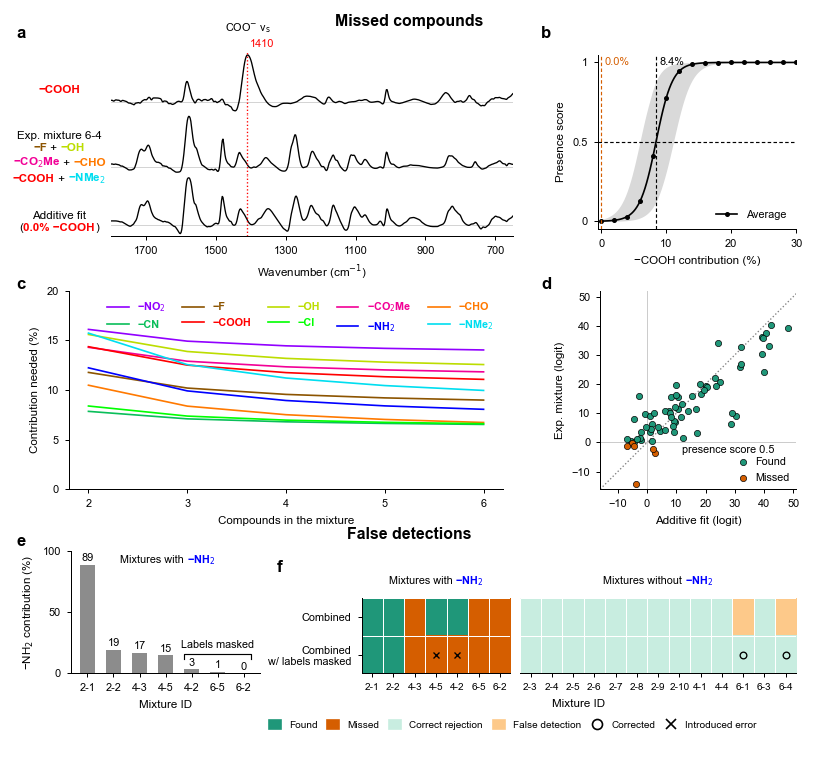

In [7]:
fig, mm = page(168, 156)
letters(mm, {"a": (1, 3), "b": (112, 3), "c": (1, 56), "d": (112, 56), "e": (1, 110.5), "f": (56, 116)})
mm.text(84, 2, "Missed compounds", ha="center", va="center", fontsize=9.5, fontweight="bold")
mm.text(84, 110.5, "False detections", ha="center", va="center", fontsize=9.5, fontweight="bold")
statistics = sheets["Fig. 6 statistics"].set_index(["Panel", "Statistic"])["Value"]
carboxylate = sheets["Fig. 5 statistics"].set_index("Comparison").loc["-COOH carboxylate band", "Value"]
observed, threshold = statistics["a", "-COOH contribution (%)"], statistics["b", "Detection threshold (%)"]

spectra = sheets["Fig. 6a"]
rows = []
for k, column in enumerate(spectra.columns[1:]):
    ax = axes(fig, 21, 8.5 + 13 * k, 85, 13)
    ax.axhline(0, color="0.8", lw=0.5)
    ax.plot(spectra[WN], spectra[column], color="black", lw=0.8)
    ax.axvline(carboxylate, color="red", ls=":", lw=0.8)
    last = k == 2
    ax.set(xlim=(1800, 650), yticks=[])
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(last)
    ax.tick_params(bottom=last, labelbottom=last, labelsize=6.5)
    if last:
        ax.set_xticks([1700, 1500, 1300, 1100, 900, 700])
        ax.set_xlabel(WN_LABEL, fontsize=7)
    rows.append(ax)
rows[0].annotate(f"{carboxylate:.0f}", (carboxylate, 1), xycoords=("data", "axes fraction"), xytext=(1.5, 2),
                 textcoords="offset points", color="red", va="bottom", fontsize=6.5)
rows[0].annotate("COO$^{-}$ ν$_\\mathrm{s}$", (carboxylate, 1), xycoords=("data", "axes fraction"), xytext=(0, 10),
                 textcoords="offset points", ha="center", va="bottom", fontsize=6.5)
formula(mm, 10, 16.5, [["COOH"]], size=7)
formula(mm, 10, 31, [["Exp. mixture 6-4"], ["F", "OH"], ["CO2Me", "CHO"], ["COOH", "NMe2"]], size=7)
formula(mm, 10, 44.5, [["Additive fit"], ["(", (f"{observed:.1f}% " + group("COOH"), COLOR["COOH"]), ")"]], size=7)

curve = sheets["Fig. 6b"]
ax = axes(fig, 124, 9, 42, 37)
x = curve.iloc[:, 0]
ax.fill_between(x, curve.iloc[:, 2], curve.iloc[:, 3], color="#D9D9D9", lw=0)
ax.plot(x, curve.iloc[:, 1], color="black", lw=1, marker="o", ms=2, markevery=8, label="Average")
ax.axhline(0.5, color="black", ls=(0, (3, 2)), lw=0.7)
for value, color in ((threshold, "black"), (observed, OUTCOME["Missed"])):
    ax.axvline(value, color=color, ls=(0, (3, 2)), lw=0.7)
    ax.text(value + 0.5, 1, f"{value:.1f}%", color=color, va="center", fontsize=6.5)
ax.set(xlim=(-0.5, 30), ylim=(-0.05, 1.05), xticks=[0, 10, 20, 30], yticks=[0, 0.5, 1], yticklabels=["0", "0.5", "1"])
ax.tick_params(labelsize=6.5)
ax.set_xlabel("−COOH contribution (%)", fontsize=7)
ax.set_ylabel("Presence score", fontsize=7)
ax.legend(loc="lower right", fontsize=6.5)

need = sheets["Fig. 6c"]
ax = axes(fig, 12, 59, 92, 42)
for c in ORDER:
    line = need[need["Compound"] == c]
    ax.plot(line["Compounds in the mixture"], line["Contribution needed (%)"], color=COLOR[c], lw=1, label=group(c))
ax.set(xlim=(1.8, 6.2), xticks=range(2, 7), ylim=(0, 20), yticks=[0, 5, 10, 15, 20])
ax.tick_params(labelsize=6.5)
ax.set_xlabel("Compounds in the mixture", fontsize=7)
ax.set_ylabel("Contribution needed (%)", fontsize=7)
handles = ax.get_legend_handles_labels()[0]
rowwise = [ORDER.index(c) for pair in zip(ORDER[:5], ORDER[5:]) for c in pair]
legend = ax.legend(handles=[handles[k] for k in rowwise], ncol=5, loc="upper right", fontsize=6.5, handlelength=2,
                   columnspacing=1.5)
for text, c in zip(legend.get_texts(), [ORDER[k] for k in rowwise]):
    text.set_color(COLOR[c])
    text.set_fontweight("bold")

logits = sheets["Fig. 6d"]
ax = axes(fig, 124.5, 59, 41.5, 42)
ax.axhline(0, color="0.8", lw=0.6)
ax.axvline(0, color="0.8", lw=0.6)
ax.axline((0, 0), slope=1, color="gray", ls=":", lw=0.8)
for found, label in ((True, "Found"), (False, "Missed")):
    points = logits[logits["Found"] == found]
    ax.scatter(points["Additive fit (logit)"], points["Experimental mixture (logit)"], s=14, color=OUTCOME[label],
               edgecolor="black", lw=0.4, label=label, zorder=3)
ax.text(12, -1, "presence score 0.5", va="top", fontsize=6.5)
ax.set(xlim=(-16, 51), ylim=(-16, 52), xticks=range(-10, 51, 10), yticks=range(-10, 51, 10))
ax.tick_params(labelsize=6.5)
ax.set_xlabel("Additive fit (logit)", fontsize=7)
ax.set_ylabel("Exp. mixture (logit)", fontsize=7)
ax.legend(loc="lower right", fontsize=6.5, handletextpad=0.2, borderaxespad=0.2)

nh2 = sheets["Fig. 6e"]
ax = axes(fig, 12.5, 114, 40, 26)
bars = ax.bar(nh2["Mixture"], nh2["-NH2 contribution (%)"], color="#8C8C8C", width=0.6)
ax.bar_label(bars, [f"{v:.0f}" for v in nh2["-NH2 contribution (%)"]], fontsize=6.5, padding=1)
masked = np.flatnonzero(nh2["Label masked"])
ax.plot([masked[0] - 0.3, masked[0] - 0.3, masked[-1] + 0.3, masked[-1] + 0.3], [12, 16, 16, 12], color="black", lw=0.7)
ax.text(masked.mean(), 19, "Labels masked", ha="center", va="bottom", fontsize=6.5)
ax.set(ylim=(0, 100), yticks=[0, 50, 100])
ax.tick_params(labelsize=6.5)
ax.set_xlabel("Mixture ID", fontsize=7)
ax.set_ylabel(group("NH2") + " contribution (%)", fontsize=7)
formula(mm, 33, 116, [["Mixtures with ", "NH2"]], size=6.5)

calls = sheets["Fig. 6f"]
prepared = calls["-NH2 prepared"].to_numpy()
cell = 4.5
for block, left, title in ((calls[prepared], 74, "Mixtures with "), (calls[~prepared], 107.5, "Mixtures without ")):
    ax = axes(fig, left, 124, cell * len(block), 16)
    outcome_grid(ax, [list(block["Combined call"]), list(block["Labels masked call"])],
                 [[""] * len(block), list(block["Change"])])
    ax.set_xticks(range(len(block)), block["Mixture"])
    ax.set_yticks([0, 1], ["Combined", "Combined\nw/ labels masked"] if left < 100 else [])
    ax.tick_params(left=left < 100, labelsize=6.5)
    ax.tick_params(axis="x", labelsize=6)
    ax.spines["left"].set_visible(left < 100)
    formula(mm, left + cell * len(block) / 2, 120.5, [[title, "NH2"]], size=6.5)
mm.text(120, 146.5, "Mixture ID", ha="center", va="center", fontsize=7)
outcome_key(mm, 106, 151, ["Found", "Missed", "Correct rejection", "False detection"], marks=True, size=6,
            spacing=1, handle=1.2)
fig.savefig("figures/figure_6.png")
plt.show()

## Supplementary Fig. S2

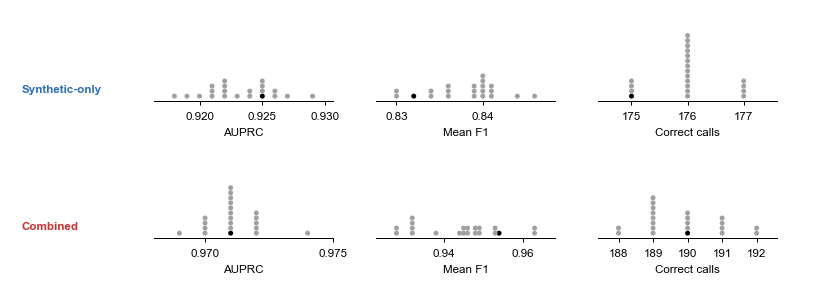

In [8]:
fig, mm = page(171, 56)
sets = sheets["Fig. S2"]
for lc, top in (("Synthetic-only", 3.5), ("Combined", 32.5)):
    rows = sets[sets["LC"] == lc].sort_values("Main text", ascending=False, kind="stable")
    mm.text(2, top + 13, lc, color=TRAINING[lc], fontweight="bold", va="center", fontsize=7)
    for left, measure, digits in ((30, "AUPRC", 3), (77, "Mean F1", 3), (124, "Correct calls", 0)):
        ax = axes(fig, left, top, 38, 15.5)
        values = rows[measure].round(digits)
        ax.scatter(values, values.groupby(values).cumcount(), s=9, lw=0,
                   color=np.where(rows["Main text"], "black", "#A0A0A0"))
        pad = max(0.15 * np.ptp(values), 0.6 if digits == 0 else 0.001)
        ax.set(xlim=(values.min() - pad, values.max() + pad), ylim=(-1, 13.5), yticks=[])
        ax.xaxis.set_major_locator(MultipleLocator(1) if digits == 0 else MaxNLocator(3, steps=[1, 2, 5, 10]))
        ax.xaxis.set_major_formatter(FormatStrFormatter({"AUPRC": "%.3f", "Mean F1": "%.2f"}.get(measure, "%d")))
        ax.spines["left"].set_visible(False)
        ax.tick_params(labelsize=7)
        ax.set_xlabel(measure, fontsize=7)
fig.savefig("figures/figure_s2.png")
plt.show()

## Supplementary Fig. S3

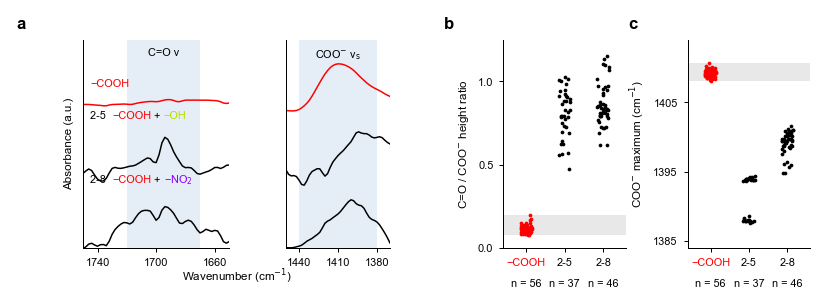

In [9]:
fig, mm = page(171, 60)
letters(mm, {"a": (1, 1), "b": (91.5, 1), "c": (130.5, 1)})
bands = sheets["Fig. S3a"]
windows = []
for left, width, xlim, window, label, ticks in ((15, 31, (1750, 1650), (1670, 1720), "C=O ν", [1740, 1700, 1660]),
                                                (58, 22, (1450, 1370), (1380, 1440), "COO$^{-}$ ν$_\\mathrm{s}$",
                                                 [1440, 1410, 1380])):
    ax = axes(fig, left, 6, width, 44)
    ax.axvspan(*window, color=BAND, lw=0, zorder=0)
    for column, color in zip(bands.columns[1:], ["red", "black", "black"]):
        ax.plot(bands[WN], bands[column].where(bands[WN].between(xlim[1], xlim[0])), color=color, lw=0.9)
    ax.text(np.mean(window), 4.8, label, ha="center", va="top", fontsize=6.5)
    ax.set(xlim=xlim, ylim=(-0.2, 5), yticks=[], xticks=ticks)
    ax.tick_params(labelsize=6.5)
    windows.append(ax)
mm.text(12, 28, "Absorbance (a.u.)", rotation=90, ha="center", va="center", fontsize=7)
mm.text(47.5, 56, WN_LABEL, ha="center", va="center", fontsize=7)
for y, tokens in ((3.9, ["COOH"]), (3.1, ["2-5  ", "COOH", "OH"]), (1.5, ["2-8  ", "COOH", "NO2"])):
    formula(windows[0], 1745, y, [tokens], loc="center left", weight="normal", size=6.5)

points = sheets["Fig. S3b,c"]
for left, column, label, ylim, ticks in ((104, "C=O / COO- height ratio", "C=O / COO$^{-}$ height ratio", (0, 1.25),
                                          [0, 0.5, 1]),
                                         (143, "Carboxylate maximum (cm-1)", "COO$^{-}$ maximum (cm$^{-1}$)",
                                          (1384, 1414), [1385, 1395, 1405])):
    ax = axes(fig, left, 6, 26, 44)
    single = points.loc[points["Sample"] == "-COOH", column]
    ax.axhspan(single.min(), single.max(), color="#E8E8E8", lw=0, zorder=0)
    for k, sample in enumerate(["-COOH", "2-5", "2-8"]):
        values = points.loc[points["Sample"] == sample, column]
        jitter = np.random.default_rng(7).uniform(-0.15, 0.15, len(values))
        ax.scatter(k + jitter, values, s=5, lw=0, color="red" if k == 0 else "black")
        ax.text(k, -0.15, f"n = {len(values)}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=6.5)
    ax.set(xlim=(-0.6, 2.6), ylim=ylim, yticks=ticks)
    ax.set_xticks([0, 1, 2], [group("COOH"), "2-5", "2-8"])
    ax.get_xticklabels()[0].set_color("red")
    ax.tick_params(labelsize=6.5)
    ax.set_ylabel(label, fontsize=7)
fig.savefig("figures/figure_s3.png")
plt.show()